<a href="https://colab.research.google.com/github/Sofia888u/S3/blob/main/tp3_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Imports

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn import datasets

2. Chargement dyal data

In [2]:
iris = datasets.load_iris()

3. Pandas DataFrame

In [4]:
x = pd.DataFrame(iris.data)
x.columns = ['Sepal_Length','Sepal_width','Petal_Length','Petal_width']
y = pd.DataFrame(iris.target)
y.columns = ['Targets']

4. Construction dyal modèle

In [5]:
model = KMeans(n_clusters=3)
model.fit(x)
model.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 1, 1, 2, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 1, 1, 2, 2, 2, 2,
       2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 1], dtype=int32)

5. Visualisation

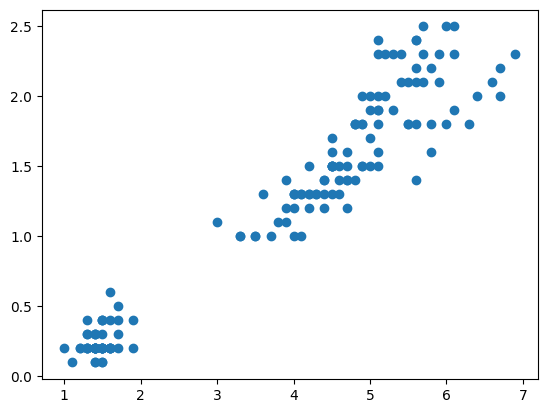

In [6]:
plt.scatter(x.Petal_Length, x.Petal_width)

6. Classification réelle (Figure 1)

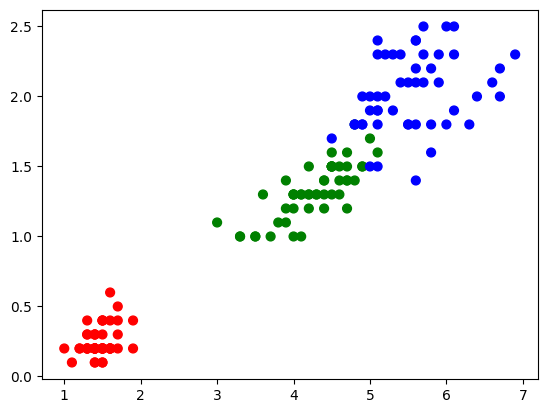

In [7]:
colormap = np.array(['Red','green','blue'])
plt.scatter(x.Petal_Length, x.Petal_width, c=colormap[y.Targets], s=40)

7. Classification K-means (Figure 2)

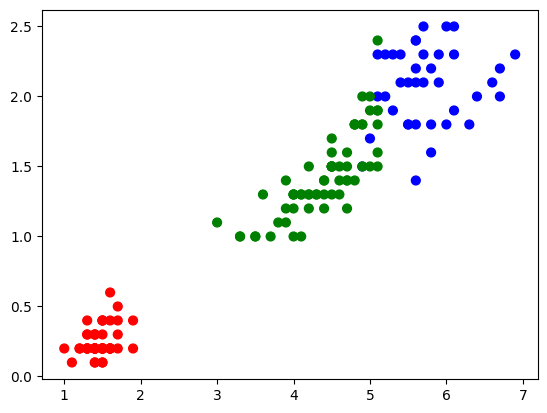

In [13]:
from scipy.stats import mode

predY = np.zeros_like(model.labels_)
for c in range(3):
    mask = (model.labels_ == c)
    predY[mask] = mode(y.Targets[mask], keepdims=True).mode[0]

plt.scatter(x.Petal_Length, x.Petal_width, c=colormap[predY], s=40)

8. Évaluation

In [14]:
from sklearn.metrics import accuracy_score, confusion_matrix

In [15]:
accuracy_score(y.Targets, predY)       # 0.893 → 89.3%
confusion_matrix(y.Targets, predY)

array([[50,  0,  0],
       [ 0, 48,  2],
       [ 0, 14, 36]])

Conclusion

L’algorithme K-Means, appliqué avec 3 clusters sur le jeu de données Iris, a permis de retrouver la structure réelle des données sans utiliser les étiquettes. La classe setosa est parfaitement isolée (50 fleurs sur 50 bien classées), car elle est très éloignée des deux autres dans l’espace des pétales. Les classes versicolor et virginica se chevauchent légèrement : 2 fleurs versicolor ont été classées comme virginica, et 14 fleurs virginica comme versicolor.

L’accuracy globale est de 89,3 % (134 fleurs bien classées sur 150). Ce résultat montre que K-Means, bien qu’étant un algorithme non supervisé, parvient à découvrir une structure très proche de la répartition réelle des données.